In [1]:
# importing necessary libraries
import os
import subprocess
import shutil
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import multiprocessing as mp
from functools import partial
import time
from scipy.interpolate import griddata
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import random
import psutil
import math

In [ ]:
# set the directory of the files
original_dir = os.getcwd()


# change to the directory where the data is located
data_dir =os.path.abspath("../Result_Files/10_Zeta_10_S/") 
os.chdir(data_dir)
print(f"Current working directory: {os.getcwd()}")
sim_indentifier = os.path.basename(data_dir)
print(f"Simulation identifier: {sim_indentifier}")

# Create a plot directory if it doesn't exist
plot_dir = os.path.join(original_dir, "Plots")
print(f"plot directory: {plot_dir}")
os.makedirs(plot_dir, exist_ok=True) 


Current working directory: /home/pkumar/Documents/Gitlab_INRIA/oocyte-selection-3d-abm-dev/run/Result_Files_Final/10_Zeta_10_S
Simulation identifier: 10_Zeta_10_S
plot directory: /home/pkumar/Documents/Gitlab_INRIA/oocyte-selection-3d-abm-dev/run/notebooks_post_processing/Plots


In [3]:
combined_data_file = os.path.join(data_dir, "combined_nurse_cell_activation.txt")
germ_summary_file = os.path.join(data_dir, "germ_cell_summary.txt")

In [4]:
def analyze_convergence_by_parameters_at_timepoint(combined_data_file, target_timepoint=None, step_size=1, cell_type="Germ"):
    """
    Analyze convergence for each parameter combination at a specific timepoint or final timepoint.
    
    Parameters:
    - combined_data_file: Path to the combined nurse cell activation data
    - target_timepoint: Specific timepoint to analyze (if None, uses final timepoint)
    - step_size: Step size for sampling different run counts
    
    Returns:
    - convergence_results: Dictionary with convergence data for each parameter combination
    """
    # Read the combined data
    data = pd.read_csv(combined_data_file, sep="\t")
    
    # Find the closest timepoint if target_timepoint is specified
    if target_timepoint is not None:
        closest_time_idx = (data['TimeStep'] - target_timepoint).abs().idxmin()
        analysis_timepoint = data.loc[closest_time_idx, 'TimeStep']
        print(f"Analyzing at timepoint: {analysis_timepoint} (requested: {target_timepoint})")
    else:
        closest_time_idx = data.index[-1]  # Last timepoint
        analysis_timepoint = data.loc[closest_time_idx, 'TimeStep']
        print(f"Analyzing at final timepoint: {analysis_timepoint}")
    
    sim_cols = [c for c in data.columns if c != 'TimeStep' and c.endswith(f"_{cell_type}")]

    param_combinations = {}
    for column in sim_cols:
        match = re.search(r"PTN_(\d+\.\d+)_ESC_(\d+\.\d+)", column)
        if not match:
            continue
        param_key = f"PTN_{match.group(1)}_ESC_{match.group(2)}"
        param_combinations.setdefault(param_key, []).append(data.loc[closest_time_idx, column])

    convergence_results = {}
    for param_key, values in param_combinations.items():
        run_counts, means, cvs = [], [], []
        max_runs = len(values)
        for n_runs in range(step_size, max_runs + 1, step_size):
            subset_values = values[:n_runs]
            mean_val = np.mean(subset_values)
            std_val = np.std(subset_values)
            cv_val = std_val / mean_val if mean_val != 0 else 0
            run_counts.append(n_runs); means.append(mean_val); cvs.append(cv_val)

        convergence_results[param_key] = pd.DataFrame({
            'n_runs': run_counts, 'mean': means, 'cv': cvs
        })

    return convergence_results, param_combinations, analysis_timepoint

# Example usage with different timepoints
print("=== Analysis at different timepoints ===")

# Analyze at timepoint 100 hours
convergence_100h, param_combinations_100h, actual_time_100h = analyze_convergence_by_parameters_at_timepoint(
    combined_data_file, target_timepoint=100, step_size=1, cell_type="Germ"
)

# Analyze at timepoint 200 hours
convergence_200h, param_combinations_200h, actual_time_200h = analyze_convergence_by_parameters_at_timepoint(
    combined_data_file, target_timepoint=200, step_size=1, cell_type="Germ"
)

# Analyze at final timepoint (same as original function)
convergence_final, param_combinations_final, actual_time_final = analyze_convergence_by_parameters_at_timepoint(
    combined_data_file, target_timepoint=None, step_size=1, cell_type="Germ"
)

=== Analysis at different timepoints ===
Analyzing at timepoint: 100.0 (requested: 100)
Analyzing at timepoint: 200.0 (requested: 200)
Analyzing at final timepoint: 240.0


In [5]:

def check_convergence_single(convergence_df, mean_tol=1, abs_cv_tol=1e-4,
                             cv_tol=0.05, window_size=5):
    """
    Check if mean and CV stabilize within desired tolerances over a rolling window.
    (Single parameter set version)
    """
    n_points = len(convergence_df)
    if n_points < window_size + 1:
        return None

    for i in range(window_size, n_points):
        recent_means = convergence_df.iloc[i-window_size:i+1]['mean'].values
        recent_cvs = convergence_df.iloc[i-window_size:i+1]['cv'].values

        # Calculate mean changes (absolute differences)
        mean_changes = [abs(recent_means[j] - recent_means[j-1])
                        for j in range(1, len(recent_means))]
        
        # Calculate CV changes (relative or absolute based on CV magnitude)
        cv_changes = [
            abs(recent_cvs[j] - recent_cvs[j-1]) / max(abs(recent_cvs[j-1]), 1e-8)
            if abs(recent_cvs[j-1]) > 0.001 and abs(recent_cvs[j]) > 0.001
            else abs(recent_cvs[j] - recent_cvs[j-1])
            for j in range(1, len(recent_cvs))
        ]

        # Check convergence conditions
        mean_converged = all(change < mean_tol for change in mean_changes)
        cv_converged = all(
            change < cv_tol if abs(recent_cvs[j-1]) > 0.001 and abs(recent_cvs[j]) > 0.001 else change < abs_cv_tol
            for j, change in enumerate(cv_changes, 1)
        )
        
        if mean_converged and cv_converged:
            return int(convergence_df.iloc[i]['n_runs'])

    return None


def check_convergence_all_parameters(convergence_results_dict, mean_tol=1, abs_cv_tol=1e-4, cv_tol=0.05, window_size=5):
    """
    Check convergence for all parameter combinations in the simulation set.
    same for the above function too
    Parameters:
    - convergence_results_dict: Dictionary where keys are parameter combinations (e.g., "PTN_2.25_ESC_4.0")
                               and values are DataFrames with columns 'n_runs', 'mean', 'cv'
    - mean_tol: Relative tolerance for mean (e.g., 0.01 for 1%)
    - cv_tol: Relative tolerance for CV (e.g., 0.01 for 1%)
    - window_size: Number of consecutive points to check for stability
    
    Returns:
    - DataFrame with convergence results for each parameter combination
    """
    results = []
    
    for param_key, convergence_df in convergence_results_dict.items():
        convergence_point = check_convergence_single(convergence_df, mean_tol, abs_cv_tol, cv_tol, window_size)

        # Get final statistics
        final_mean = convergence_df.iloc[-1]['mean']
        final_cv = convergence_df.iloc[-1]['cv']
        max_runs = convergence_df.iloc[-1]['n_runs']
        
        results.append({
            'Parameter_Combination': param_key,
            'Convergence_Point': convergence_point,
            'Final_Mean': final_mean,
            'Final_CV': final_cv,
            'Max_Runs_Available': max_runs,
            'Converged': 'Yes' if convergence_point is not None else 'No',
            'Mean_Tolerance': mean_tol,
            'CV_Tolerance': cv_tol,
            'Abs_CV_Tolerance': abs_cv_tol,
            'Window_Size': window_size
        })
    
    return pd.DataFrame(results)

def analyze_convergence_across_timepoints(convergence_100h, convergence_200h, convergence_final,
                                         actual_time_100h, actual_time_200h, actual_time_final,
                                         mean_tol=1, abs_cv_tol=1e-4, cv_tol=0.05, window_size=5):
    """
    Analyze convergence across multiple timepoints for all parameter combinations.
    
    Parameters:
    - convergence_100h, convergence_200h, convergence_final: Dictionaries of convergence results
    - actual_time_*: Actual timepoints
    - mean_tol, cv_tol, window_size: Convergence criteria
    
    Returns:
    - DataFrame with convergence analysis across all timepoints
    """
    timepoint_data = [
        (convergence_100h, f"{actual_time_100h}h"),
        (convergence_200h, f"{actual_time_200h}h"),
        (convergence_final, f"{actual_time_final}h (Final)")
    ]
    
    all_results = []
    
    for conv_dict, timepoint_label in timepoint_data:
        timepoint_results = check_convergence_all_parameters(conv_dict, mean_tol, abs_cv_tol, cv_tol, window_size)
        timepoint_results['Timepoint'] = timepoint_label
        all_results.append(timepoint_results)
    
    # Combine all results
    combined_results = pd.concat(all_results, ignore_index=True)
    
    # Reorder columns for better readability
    column_order = ['Timepoint', 'Parameter_Combination', 'Converged', 'Convergence_Point', 
                   'Final_Mean', 'Final_CV', 'Max_Runs_Available', 'Mean_Tolerance', 
                   'CV_Tolerance', 'Window_Size']
    combined_results = combined_results[column_order]
    
    return combined_results

# Example usage with your data:
print("=== Convergence Analysis for All Parameter Combinations ===")

# Analyze across all timepoints
comprehensive_analysis = analyze_convergence_across_timepoints(
    convergence_100h, convergence_200h, convergence_final,
    actual_time_100h, actual_time_200h, actual_time_final,
    mean_tol= 1.0, cv_tol=0.05, window_size=5
)


=== Convergence Analysis for All Parameter Combinations ===


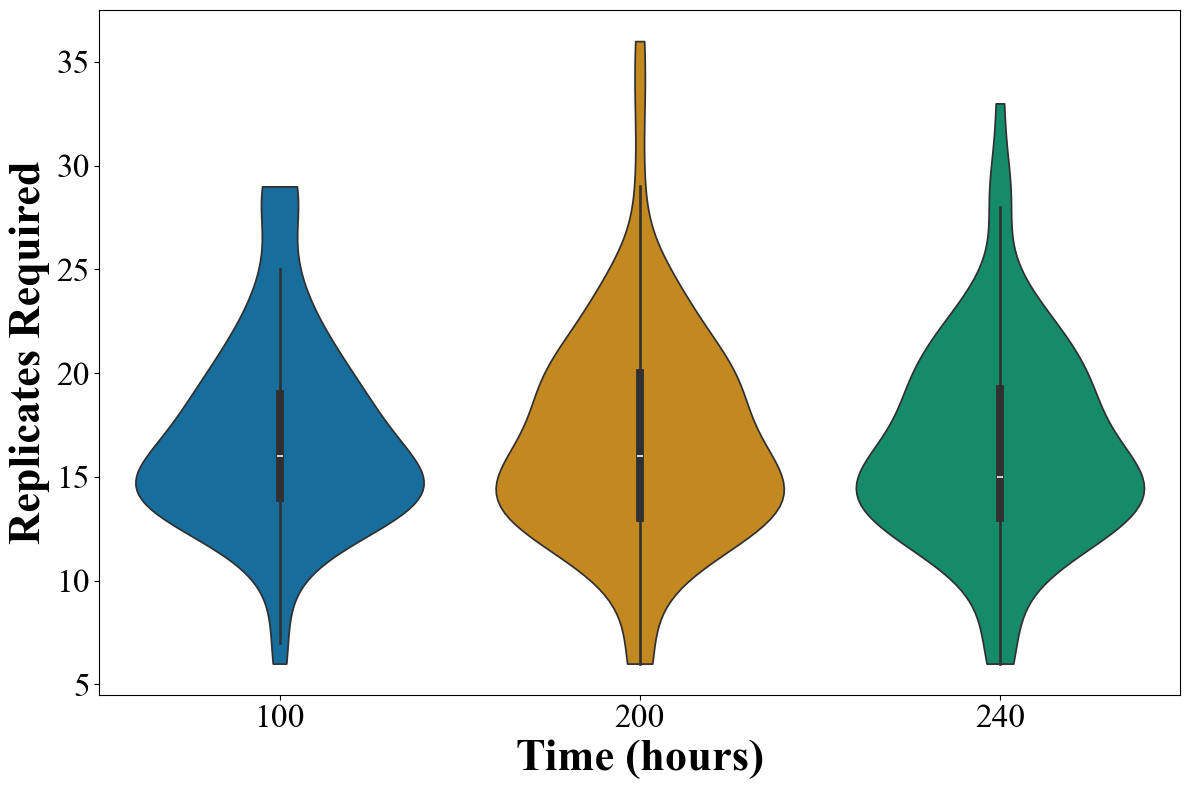

In [8]:
def plot_convergence_results_focused(comprehensive_analysis):
    """
    Plot focused results: mean, CV, and minimum simulations for converged parameter combinations
    """
    # Filter only converged cases
    converged_data = comprehensive_analysis[comprehensive_analysis['Converged'] == 'Yes'].copy()
    
    if len(converged_data) == 0:
        print("No converged parameter combinations found!")
        return
    
   
    return converged_data

def create_convergence_summary_table(comprehensive_analysis):
    """
    Create a clean summary table with only essential convergence information
    """
    # Filter only converged cases
    converged_data = comprehensive_analysis[comprehensive_analysis['Converged'] == 'Yes'].copy()
    
    if len(converged_data) == 0:
        print("No converged parameter combinations found!")
        return None
    
    # Select only the key columns
    summary_cols = ['Parameter_Combination', 'Timepoint', 'Final_Mean', 'Final_CV', 'Convergence_Point']
    summary_table = converged_data[summary_cols].copy()
    
    # Round values for better display
    summary_table['Final_Mean'] = summary_table['Final_Mean'].round(3)
    summary_table['Final_CV'] = summary_table['Final_CV'].round(4)
    summary_table['Convergence_Point'] = summary_table['Convergence_Point'].astype(int)
    
    # Sort for better readability
    summary_table = summary_table.sort_values(['Parameter_Combination', 'Timepoint'])
    
    print("=== Convergence Summary: Mean, CV, and Minimum Simulations ===")
    print(summary_table.to_string(index=False))
    
    # Export to files
    summary_table.to_csv("convergence_summary_focused.txt", sep="\t", index=False)
    with open("convergence_summary_focused.tex", "w") as f:
        f.write(summary_table.to_latex(index=False, float_format="%.4f"))
    
    return summary_table

def plot_comparative_analysis(comprehensive_analysis):
    """
    Create comparative plots showing trends across timepoints
    """
    converged_data = comprehensive_analysis[comprehensive_analysis['Converged'] == 'Yes'].copy()
    
    if len(converged_data) == 0:
        print("No converged parameter combinations found!")
        return
    
    # Extract numeric timepoint values from strings like "100.0h", "200.0h", "480.0h (Final)"
    def extract_timepoint_value(timepoint_str):
        # Extract first number from string
        match = re.search(r'(\d+(?:\.\d+)?)', str(timepoint_str))
        return float(match.group(1)) if match else 0
    
    converged_data['Timepoint_Numeric'] = converged_data['Timepoint'].apply(extract_timepoint_value)
    
    # Sort by numeric timepoint to ensure proper ordering
    converged_data = converged_data.sort_values('Timepoint_Numeric')
    
    # Create labels with just numeric values (without 'h' suffix)
    converged_data['Timepoint_Label'] = converged_data['Timepoint_Numeric'].astype(int).astype(str)
    
    # Create ordered categories for plotting
    timepoint_order = sorted(converged_data['Timepoint'].unique(), 
                            key=lambda x: extract_timepoint_value(x))
    
    
    fig, axes = plt.subplots(figsize=(12, 8))
    # Simulations required by timepoint (violin plot)
    sns.violinplot(data=converged_data, x='Timepoint_Label', y='Convergence_Point', ax=axes, 
                   inner='box', cut=0, palette='colorblind', hue='Timepoint_Label')
    # axes.set_title('Distribution of Simulations Required by Timepoint', fontsize=24, fontweight='bold')
    axes.set_xlabel('Time (hours)', fontsize=32, fontweight='bold', fontfamily='Times New Roman')
    axes.set_ylabel('Replicates Required', fontsize=32, fontweight='bold', fontfamily='Times New Roman')    
    axes.tick_params(axis='x', rotation=0, labelsize=24)
    axes.tick_params(axis='y', labelsize=24)

    for label in axes.get_xticklabels() + axes.get_yticklabels():
        label.set_fontfamily('Times New Roman')
        # label.set_fontweight('bold')
    
    plt.tight_layout()
    plt.savefig(os.path.join(plot_dir, "simulations_required_by_timepoint" + sim_indentifier + '.png'), dpi=300)
    plt.show()
    

    
# Create visualizations
converged_results = plot_convergence_results_focused(comprehensive_analysis)
plot_comparative_analysis(comprehensive_analysis)



In [9]:
os.chdir(original_dir)